# EndekGAN-T2I — Dataset & Preprocessing Audit

**Dokumentasi berbasis data aktual untuk eksperimen Text-to-Image motif Endek Bali**

**PUBLIC RELEASE:** The original/resize/crop/augmentation image galleries are intentionally excluded from saved outputs to avoid redistributing Endek source images. Run the notebook against an authorized local dataset to render them. Summary counts, plots and flowchart are retained.

**Ringkasan:** Dataset sumber berisi **370 citra unik** dari empat kelas: **147 flora, 53 fauna, 112 dekoratif, 58 geometris** (512 × 512). Preprocessing final V1 meliputi **full-image resize 256 × 256** dan **class-balanced photometric augmentation** khusus training sehingga tersedia **944 train + 37 validation + 37 test = 1.018 file**. Cropping **bukan bagian dataset final V1**; notebook ini menampilkan demo *center crop* dan *candidate crop* dari arsip pilot untuk dibandingkan secara visual, tanpa menambah file training.

**Asal penelitian:** [Repository EndekGAN-T2I](https://github.com/wiwik-instiki/EndekGAN-T2I). Notebook ini **hanya memeriksa dataset**, bukan menjalankan pelatihan GAN. Seluruh keluaran augmentasi berasal dari 370 citra sumber, bukan 1.018 motif independen.

**Isi:** (1) inventaris sumber → (2) pembagian dataset → (3) resize/cropping dengan contoh visual → (4) augmentasi dan keseimbangan kelas → (5) kesesuaian CSV Text-to-Image → (6) pemeriksaan kualitas dan kesimpulan.

## 1. Setup, lokasi data dan asumsi

Notebook membaca data langsung dari drive **D:** pada komputer riset; **tidak memodifikasi atau menghapus gambar**. Kode membutuhkan Python, `pandas`, `numpy`, `Pillow`, dan `matplotlib`.

**Catatan metodologis:** Sumber gambar merupakan koleksi motif Endek Bali yang digunakan penelitian. Atribut deskriptif pada metadata telah tersedia, tetapi kesesuaian setiap kalimat prompt terhadap gambar belum diuji secara independen. Penilaian pakar direncanakan setelah model menghasilkan gambar baru.

In [ ]:
from pathlib import Path
import io, zipfile, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps
from matplotlib.patches import Rectangle

import os
BASE = Path(os.environ.get("ENDEKGAN_EXPERIMENT_ROOT", r"D:\DISERTASI_S3\WIWIK\EXPERIMEN_2"))
RAW = BASE / "ENDEK_Dataset"
PROC = BASE / "ENDEK_AUGMENTED_V1"
PROJECT = BASE / "ENDEK_T2I_EXPERIMENT_V2"

CSV_T2I = PROC / "metadata_expert_guided_T2I_augmented_V1.csv"
CSV_MANIFEST = PROC / "augmentation_manifest.csv"
PILOT_ARCHIVE = PROC / "PILOT_AUDIT_ARCHIVE_20261112.zip"
FLOWCHART = PROC / "FLOWCHART_PREPROCESSING_ENDEK.png"

CLASSES = ("flora", "fauna", "dekoratif", "geometris")
CLASS_COLOR = {"flora": "#387A61", "fauna": "#C27D4B",
               "dekoratif": "#686BA4", "geometris": "#437EA5"}
plt.rcParams.update({
    "figure.facecolor":"white", "axes.facecolor":"white", "font.size":10,
    "axes.spines.top":False,"axes.spines.right":False,"savefig.facecolor":"white"
})
required = [RAW, PROC, CSV_T2I, CSV_MANIFEST, PILOT_ARCHIVE, FLOWCHART]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Input tidak ditemukan: " + " | ".join(missing))
print("Dataset asli :", RAW)
print("Dataset final:", PROC)
print("Metadata T2I :", CSV_T2I.name)
print("Arsip pilot  :", PILOT_ARCHIVE.name)

## 2. Inventaris gambar asli (empat kelas)

Inventaris dihitung ulang dari folder kelas yang benar-benar ada. Sebelumnya ada 372 berkas tetapi dua salinan identik telah dihapus; kini terdapat **370 gambar sumber unik**. Jumlah ini tidak bertambah karena resizing, cropping, atau augmentasi.

In [ ]:
raw_paths = {c:sorted((RAW/c).glob("*.jpg")) for c in CLASSES}
raw_count = pd.Series({c:len(raw_paths[c]) for c in CLASSES}, name="Jumlah gambar asli")
assert raw_count.to_dict() == {"flora":147, "fauna":53, "dekoratif":112, "geometris":58}
print(pd.DataFrame({
    "Kelas":raw_count.index,
    "Gambar asli":raw_count.values,
    "Persentase":(raw_count.values/raw_count.sum()*100).round(2)
}).to_string(index=False))
print(f"\nTotal gambar asli: {raw_count.sum()}")

    Kelas  Gambar asli  Persentase
    flora          147       39.73
    fauna           53       14.32
dekoratif          112       30.27
geometris           58       15.68

Total gambar asli: 370


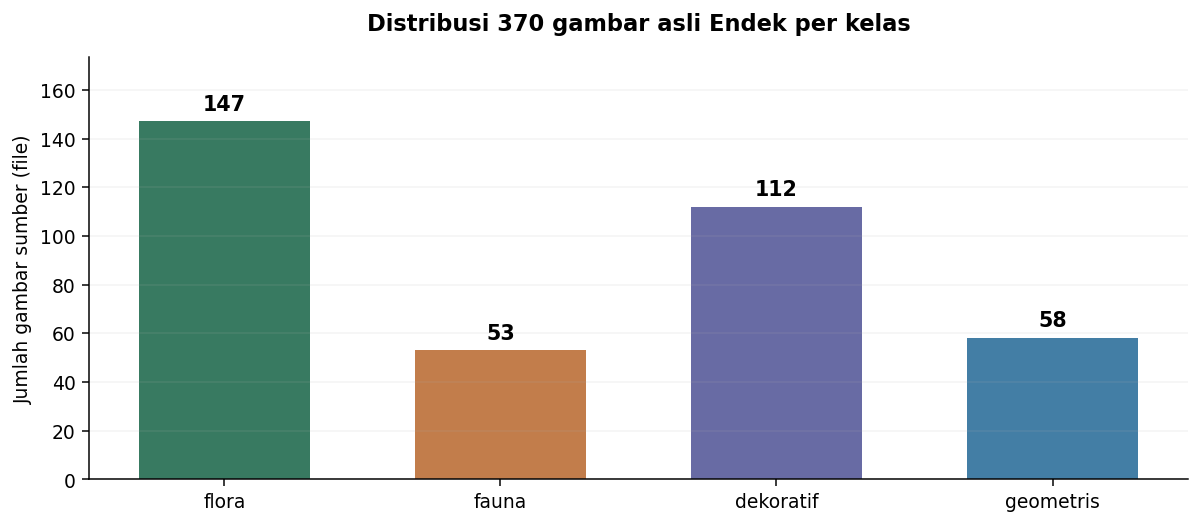

In [ ]:
fig,ax = plt.subplots(figsize=(9,4))
bars=ax.bar(raw_count.index, raw_count.values,
            color=[CLASS_COLOR[c] for c in raw_count.index], width=.62)
ax.bar_label(bars,padding=4,fontsize=11,weight="bold")
ax.set_ylabel("Jumlah gambar sumber (file)")
ax.set_title("Distribusi 370 gambar asli Endek per kelas",weight="bold",pad=14)
ax.set_ylim(0,max(raw_count.values)*1.18)
ax.grid(axis="y",alpha=.15)
plt.tight_layout()
plt.show()

## 3. Pembagian dataset sebelum augmentasi

Unit pembagian data adalah **gambar asli**. Semua varian turunan dari gambar yang sama harus berada pada split yang sama, untuk mencegah kebocoran data. Split baru memiliki jumlah **296 train / 37 validation / 37 test**, tetapi satu pasangan gambar flora yang mirip pernah dikelompokkan ulang sehingga **keanggotaan split tidak sepenuhnya sama** dengan eksperimen paper sebelumnya.

In [ ]:
df = pd.read_csv(CSV_T2I, encoding="utf-8-sig", keep_default_na=False)
aug_manifest = pd.read_csv(CSV_MANIFEST,encoding="utf-8-sig",keep_default_na=False)
assert len(df)==1018 and len(aug_manifest)==1018

df["is_aug_bool"] = df["is_augmented"].astype(str).eq("1")
original_rows = df[~df["is_aug_bool"]].copy()
assert len(original_rows)==370
split_counts = pd.crosstab(original_rows["label"],original_rows["split"]).reindex(
    CLASSES,fill_value=0
).reindex(columns=["train","val","test"],fill_value=0)
split_counts["Total"]=split_counts.sum(axis=1)
print(split_counts.to_string())
print("\nJumlah sumber pada tiap split:",original_rows.groupby("split").size().to_dict())
assert split_counts[["train","val","test"]].sum().to_dict()=={"train":296,"val":37,"test":37}

split      train  val  test  Total
label                             
flora        118   14    15    147
fauna         42    6     5     53
dekoratif     90   11    11    112
geometris     46    6     6     58

Jumlah sumber pada tiap split: {'test': 37, 'train': 296, 'val': 37}


## 4. Visualisasi citra asli setiap kelas

Gambar di bawah merupakan contoh **gambar sumber 512 × 512** dari masing-masing kelas. Visualisasi ini tidak dianggap sebagai sampel sintetis GAN.

In [ ]:
def load_rgb(path):
    with Image.open(path) as image:
        return ImageOps.exif_transpose(image).convert("RGB")

fig,axes = plt.subplots(1,4,figsize=(13,3.6))
for ax,cl in zip(axes,CLASSES):
    image=load_rgb(raw_paths[cl][0])
    ax.imshow(image)
    ax.set_title(f"{cl.capitalize()} | {image.width}×{image.height}",weight="bold")
    ax.axis("off")
fig.suptitle("Contoh motif Endek asli, masing-masing satu kelas",fontsize=15,weight="bold")
plt.tight_layout()
plt.show()

## 5. Perbandingan preprocessing: original → resize → cropping → augmentasi

**Perbedaan statusnya harus jelas:**

- **Asli:** citra sumber Endek 512 × 512.
- **Resize final V1:** seluruh gambar menjadi 256 × 256 dengan Lanczos; komposisi dipertahankan.
- **Center crop demo:** area tengah 384 × 384 dari citra asli lalu diperkecil menjadi 256 × 256; **bukan dataset final**.
- **Candidate crop pilot:** area 384 × 384 yang dipilih pilot berbasis tekstur/tepi, koordinat dipulihkan dari ZIP arsip lalu diperkecil menjadi 256 × 256; **bukan validasi unit motif** dan **tidak digunakan pada dataset training V1**.
- **Augmentasi final V1:** citra resize dengan perubahan ringan brightness, contrast, saturation, sharpness; **hanya training**.

**Catatan:** Cropping 384/512 pada kedua sisi mempertahankan 56,25% luas sumber, sehingga 43,75% area asli dibuang. Proses crop secara sembarang dapat memotong komposisi motif atau unit pengulangan.

In [ ]:
with zipfile.ZipFile(PILOT_ARCHIVE) as z:
    archive_matches=[n for n in z.namelist() if n.endswith("source_split_crop_manifest.csv")]
    assert len(archive_matches)==1,archive_matches
    with z.open(archive_matches[0]) as stream:
        pilot=pd.read_csv(stream,encoding="utf-8-sig",keep_default_na=False)
assert len(pilot)==370
pilot["relative_path"] = pilot["class"].astype(str) + "/" + pilot["file_name"].astype(str)
pilot_index=pilot.set_index("relative_path")
train_originals=original_rows[original_rows["split"]=="train"]
samples=[]
for cl in CLASSES:
    choices=train_originals[train_originals["label"]==cl].sort_values("source_filename")
    for _,r in choices.iterrows():
        candidates=df[(df["source_sha256"]==r["source_sha256"]) & (df["augmentation_variant"]=="aug01")]
        if len(candidates)==1 and r["source_filename"] in pilot_index.index:
            samples.append((cl,r,candidates.iloc[0],pilot_index.loc[r["source_filename"]]))
            break
assert len(samples)==4,"Contoh sumber/aug/pilot tidak lengkap"
print("Sumber per kelas untuk galeri:")
for cl,r,aug,roi in samples:
    print(" ",cl,"->",r["source_filename"],"|",aug["augmentation_variant"])

In [ ]:
column_titles=[
    "Gambar asli\n512×512","Asli + ROI pilot",
    "Full-image resize\n256×256","Center crop 384\n→ 256×256",
    "Pilot candidate crop\n→ 256×256","Foto augmentasi V1\n256×256"
]
fig,axes=plt.subplots(4,6,figsize=(17,12))
for row_index,(cl,r,aug,roi) in enumerate(samples):
    source_path=RAW/r["source_filename"]
    original=load_rgb(source_path)
    assert original.size==(512,512),(source_path,original.size)
    resized=original.resize((256,256),Image.Resampling.LANCZOS)
    cbox=(64,64,448,448)
    center=original.crop(cbox).resize((256,256),Image.Resampling.LANCZOS)
    box=tuple(int(roi[k]) for k in ["crop_x0","crop_y0","crop_x1","crop_y1"])
    candidate=original.crop(box).resize((256,256),Image.Resampling.LANCZOS)
    original_with_roi=original.copy()
    ImageDraw.Draw(original_with_roi).rectangle(box,outline="#F5A33A",width=9)
    augmented=load_rgb(aug["image_path"])
    images=[original,original_with_roi,resized,center,candidate,augmented]
    for col_index,(ax,img) in enumerate(zip(axes[row_index],images)):
        ax.imshow(img)
        ax.axis("off")
        if row_index==0:ax.set_title(column_titles[col_index],fontsize=10,weight="bold",pad=10)
        if col_index==0:ax.text(-0.04,.5,cl.capitalize(),transform=ax.transAxes,
           rotation=90,ha="right",va="center",fontsize=12,weight="bold",color=CLASS_COLOR[cl])
fig.suptitle("Perbandingan nyata: original, resize, cropping pilot dan augmentasi",
             fontsize=16,weight="bold",y=.998)
plt.subplots_adjust(wspace=.07,hspace=.13,left=.06,right=.99,top=.91,bottom=.03)
plt.show()

### Interpretasi galeri

- **Resize** mempertahankan keseluruhan pola namun mengurangi resolusi detail.
- **Cropping** memperbesar proporsi detail lokal, tetapi dapat memutus ornamen tepi, pola berulang dan hubungan antarornamen.
- **Augmentasi fotometrik** mempertahankan susunan bentuk dan hanya memvariasikan karakteristik warna/kontras/ketajaman.
- **Tidak ada foto hasil cropping** yang dimasukkan ke 944 file training V1. Galeri crop dihitung ulang saat notebook dijalankan menggunakan koordinat arsip pilot.

## 6. Jumlah dataset hasil augmentasi (kondisi final)

Target penyeimbangan kelas adalah **236 file training untuk setiap kelas**. Sebanyak **648 varian baru** dibuat dari 296 gambar asli pada training saja. Validation dan test tidak diperbanyak.

In [ ]:
raw_train=df[(df["split"]=="train") & (~df["is_aug_bool"])].groupby("label").size().reindex(CLASSES,fill_value=0)
generated=df[(df["split"]=="train") & (df["is_aug_bool"])].groupby("label").size().reindex(CLASSES,fill_value=0)
valid=df[df["split"]=="val"].groupby("label").size().reindex(CLASSES,fill_value=0)
test=df[df["split"]=="test"].groupby("label").size().reindex(CLASSES,fill_value=0)
summary=pd.DataFrame({
    "Gambar sumber total":raw_count, "Train asli (resized)":raw_train,
    "Varian augmentasi":generated, "Train akhir":raw_train+generated,
    "Validation":valid, "Testing":test
})
summary.index.name="Kelas"
summary.loc["TOTAL"]=summary.sum()
print(summary.to_string())
assert (raw_train+generated).to_dict()==dict.fromkeys(CLASSES,236)
assert summary.loc["TOTAL"].to_dict()=={
    "Gambar sumber total":370,"Train asli (resized)":296,"Varian augmentasi":648,
    "Train akhir":944,"Validation":37,"Testing":37
}
print("\nTotal output final:",944+37+37,"gambar; sumber independen:",370)

           Gambar sumber total  Train asli (resized)  Varian augmentasi  Train akhir  Validation  Testing
Kelas                                                                                                    
flora                      147                   118                118          236          14       15
fauna                       53                    42                194          236           6        5
dekoratif                  112                    90                146          236          11       11
geometris                   58                    46                190          236           6        6
TOTAL                      370                   296                648          944          37       37

Total output final: 1018 gambar; sumber independen: 370


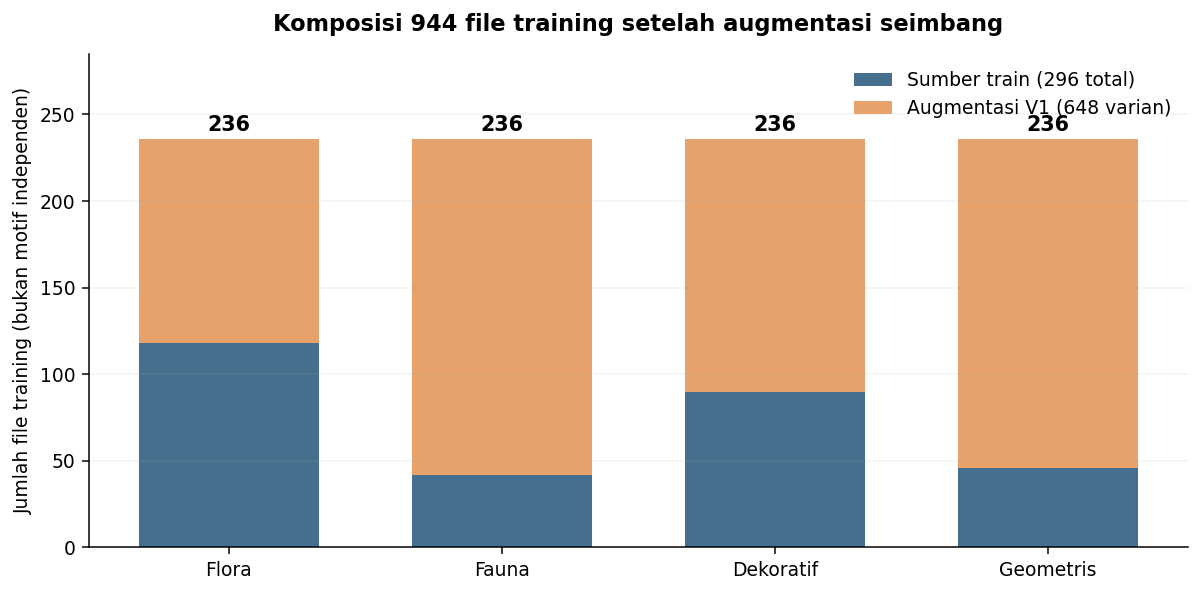

In [ ]:
fig,ax=plt.subplots(figsize=(9,4.5))
x=np.arange(len(CLASSES))
bar1=ax.bar(x,raw_train.values,width=.66,color="#456F8E",label="Sumber train (296 total)")
bar2=ax.bar(x,generated.values,width=.66,bottom=raw_train.values,
             color="#E6A26A",label="Augmentasi V1 (648 varian)")
for i,cl in enumerate(CLASSES):
    ax.text(i,238,str(int(raw_train[cl]+generated[cl])),ha="center",
            va="bottom",fontsize=11,weight="bold")
ax.set_xticks(x, [c.capitalize() for c in CLASSES])
ax.set_ylabel("Jumlah file training (bukan motif independen)")
ax.set_ylim(0,285)
ax.set_title("Komposisi 944 file training setelah augmentasi seimbang",weight="bold",pad=12)
ax.legend(frameon=False,loc="upper right")
ax.grid(axis="y",alpha=.15)
plt.tight_layout()
plt.show()

## 7. Kaitan terhadap CSV Text-to-Image

Preprocessing tidak mengubah tujuan: **prompt teks → encoder → conditional GAN → gambar motif Endek**. Semua gambar V1 tetap mempunyai `prompt`, `class_idx`, `technique`, `layout_pattern`, dan `source_sha256`. Setiap varian mengacu pada prompt sumber yang sama. Karena warna difotometrik sedikit diubah, periksa kembali kecocokan atribut warna dalam prompt saat eksperimen.

Keempat **kelas motif** (flora/fauna/dekoratif/geometris) **berbeda** dari kategori **tata letak** (pola tunggal/acak/himpunan/menyeluruh). Metadata tata letak sudah tersedia tetapi belum diverifikasi semantik setiap gambar.

In [ ]:
meta_source=original_rows.copy()
attr = pd.DataFrame({
    "Atribut": ["Citra hasil V1", "Gambar sumber", "Prompt berbeda",
                "Teks kosong", "Sumber tanpa label teknik", "Sumber tanpa pola tata letak"],
    "Jumlah": [len(df),meta_source["source_sha256"].nunique(),
               meta_source["prompt"].nunique(),
               int(df["prompt"].astype(str).str.strip().eq("").sum()),
               int(meta_source["technique"].astype(str).str.strip().eq("").sum()),
               int(meta_source["layout_pattern"].astype(str).str.strip().eq("").sum())]
})
print(attr.to_string(index=False))
assert df.groupby("source_sha256")["prompt"].nunique().max()==1
print("\nDistribusi teknik desain:")
print(meta_source["technique"].value_counts().to_string())
print("\nDistribusi tata letak:")
print(meta_source["layout_pattern"].value_counts().to_string())

                     Atribut  Jumlah
              Citra hasil V1    1018
               Gambar sumber     370
              Prompt berbeda     369
                 Teks kosong       0
   Sumber tanpa label teknik       0
Sumber tanpa pola tata letak       0

Distribusi teknik desain:
technique
deformasi    137
stilasi      122
distorsi     111

Distribusi tata letak:
layout_pattern
pola ulang himpunan      107
pola tunggal              93
pola acak terkontrol      86
pola ulang menyeluruh     84


## 8. Flowchart preprocessing yang telah dieksekusi

Flowchart berikut mendeskripsikan **V1 yang sebenarnya digunakan** (resize + augmentasi). Crop tetap merupakan cabang eksplorasi pada galeri di atas, bukan jalur pembentukan 944 file training.

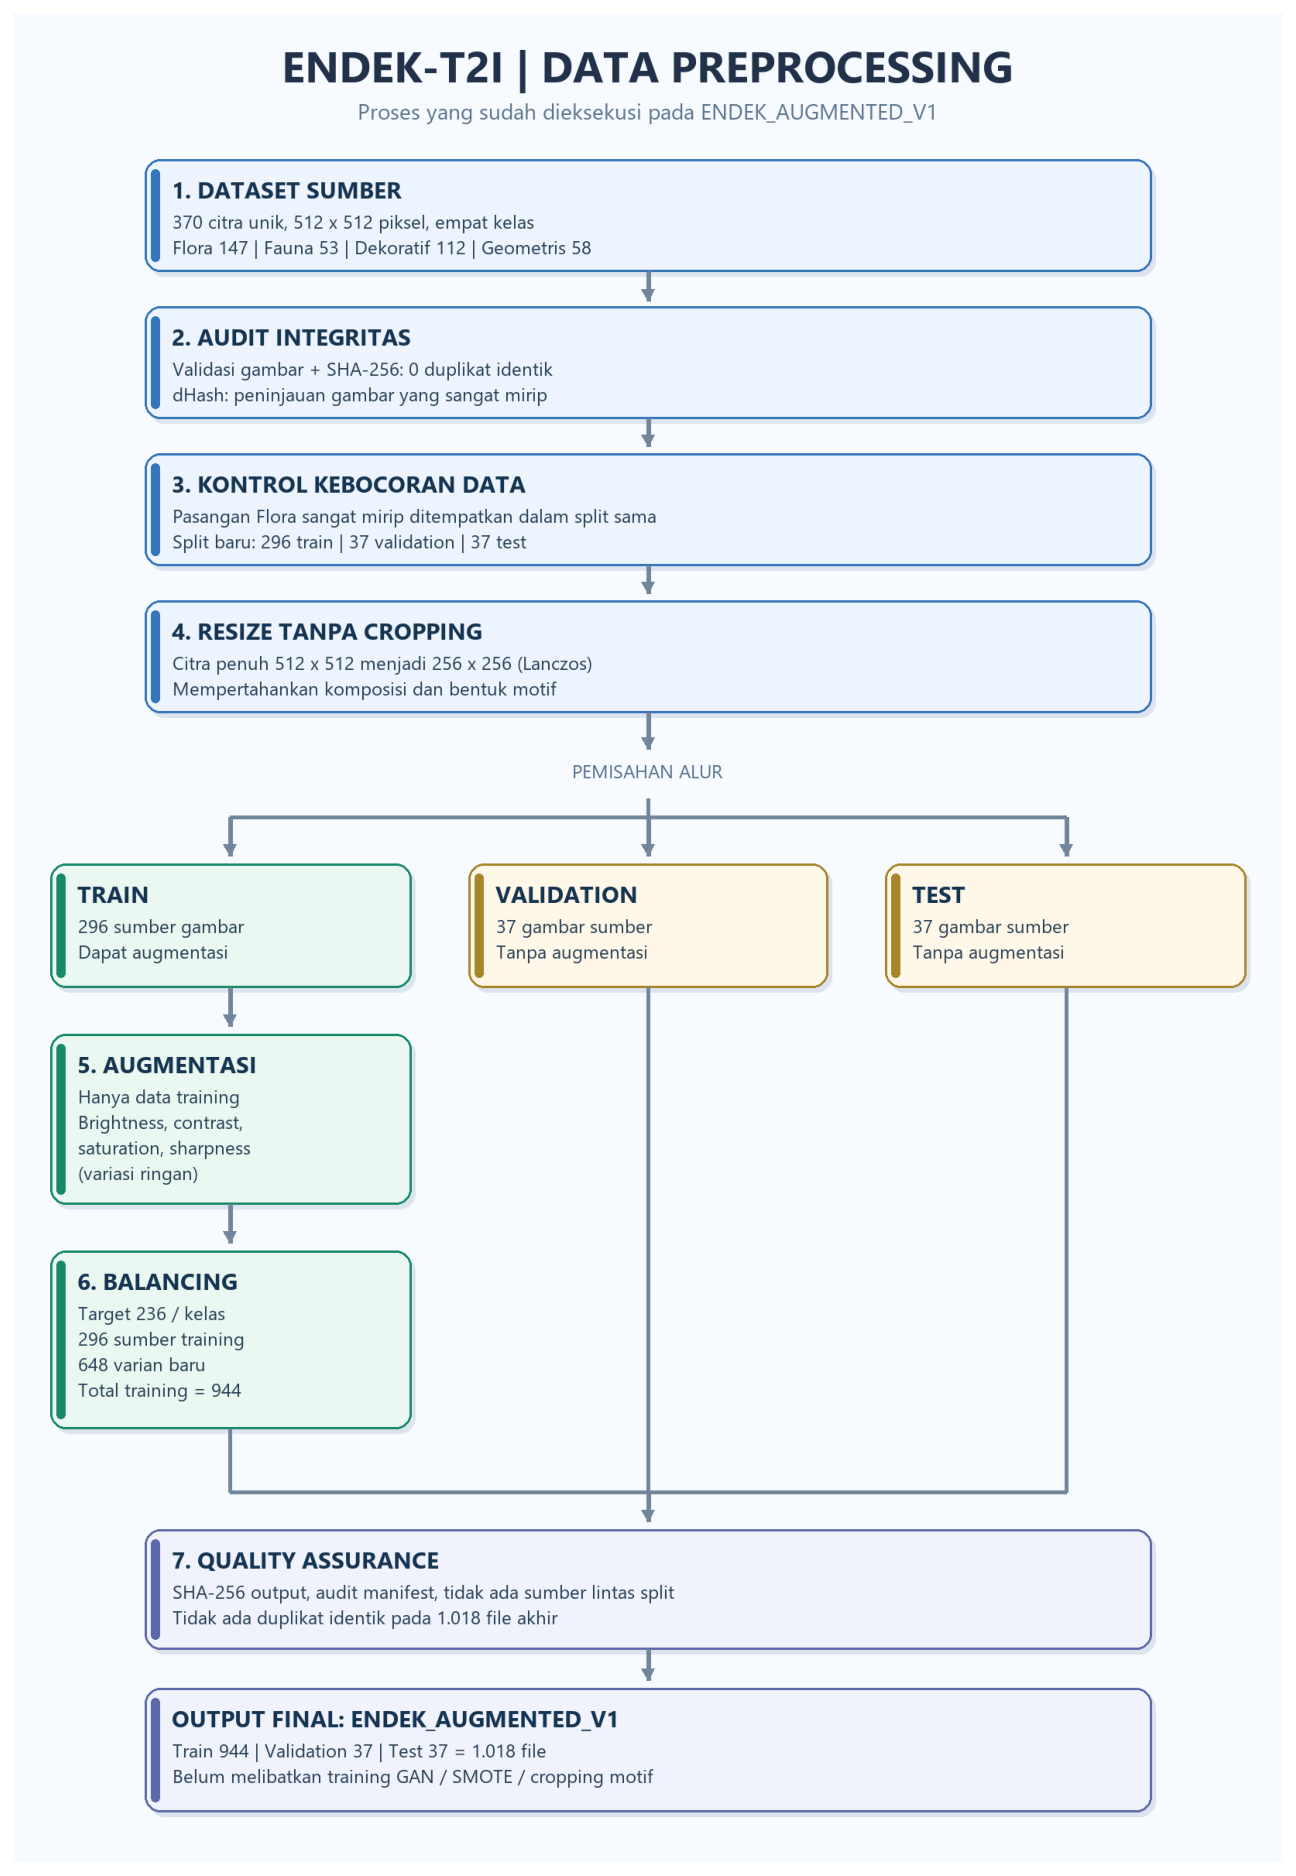

In [ ]:
flow=load_rgb(FLOWCHART)
fig,ax=plt.subplots(figsize=(10,14))
ax.imshow(flow)
ax.axis("off")
plt.tight_layout()
plt.show()

## 9. Audit integritas akhir

Memeriksa semua file dan resolusi output, jumlah sumber, aturan augmentasi hanya pada training, kecocokan checksum identitas sumber dalam manifest, serta tidak adanya sumber yang tersebar ke lebih dari satu split.

In [ ]:
missing_paths=[p for p in df["image_path"] if not Path(p).is_file()]
bad_dims=[]
for filename in df["image_path"]:
    with Image.open(filename) as im:
        if im.size != (256,256):bad_dims.append((filename,im.size))

sources_across_splits=df.groupby("source_sha256")["split"].nunique()
val_or_test_aug = df[(df["split"].isin(["val","test"])) & (df["is_aug_bool"])]
assert not missing_paths and not bad_dims
assert len(sources_across_splits)==370 and sources_across_splits.max()==1
assert len(val_or_test_aug)==0
assert df.groupby("source_sha256")["prompt"].nunique().max()==1

checks={
    "Jumlah gambar sumber unik":len(sources_across_splits),
    "Output preprocessing V1":len(df),
    "File keluaran hilang":len(missing_paths),
    "Resolusi keluaran selain 256×256":len(bad_dims),
    "Sumber muncul lintas split":int((sources_across_splits>1).sum()),
    "Val/test mengandung augmentasi":len(val_or_test_aug),
    "Sumber dengan prompt bertentangan antarturunan":
        int((df.groupby("source_sha256")["prompt"].nunique()>1).sum())
}
for key,value in checks.items():print(f"{key}: {value}")
print("\nSTATUS: SEMUA PEMERIKSAAN STRUKTURAL LULUS")

Jumlah gambar sumber unik: 370
Output preprocessing V1: 1018
File keluaran hilang: 0
Resolusi keluaran selain 256×256: 0
Sumber muncul lintas split: 0
Val/test mengandung augmentasi: 0
Sumber dengan prompt bertentangan antarturunan: 0

STATUS: SEMUA PEMERIKSAAN STRUKTURAL LULUS


## 10. Kesimpulan dan keputusan untuk EndekGAN-T2I

1. **Citra asli:** 370 gambar unik dalam empat kelas dan resolusi 512 × 512.
2. **Resize aktual:** 370 gambar sumber menjadi 256 × 256 tanpa memotong motif.
3. **Cropping:** contoh `center crop` dan kandidat dari pilot 384 × 384 → 256 × 256 ditampilkan untuk analisis; **bukan** dataset training V1 dan belum tervalidasi sebagai *motif-aware crop*.
4. **Augmentasi aktual:** 648 varian fotometrik hanya pada 296 gambar sumber training, sehingga terdapat **944 train, 37 val, 37 test**.
5. **Konsep T2I tidak berubah:** setiap keluaran tetap dipasangkan dengan prompt CSV sumber. Keaslian citra Endek tidak otomatis berarti semua atribut prompt tepat secara semantik.
6. **Eksperimen lanjutan:** gunakan 944 training V1 dan pembanding 296 training sumber pada split yang sama; evaluasi FID/KID secara hati-hati (37 gambar test), seam, keragaman, kesesuaian prompt, dan **pakar menilai gambar AI pada tahap akhir**.
7. **Batasan:** preprocessing sendiri belum membuktikan bahwa GAN lebih baik, lebih cepat atau menghasilkan motif budaya yang dapat ditenun.

**Sumber dan reproducibility:** `ENDEK_Dataset/` (asli), `ENDEK_AUGMENTED_V1/augmentation_manifest.csv`, `metadata_expert_guided_T2I_augmented_V1.csv`, `PILOT_AUDIT_ARCHIVE_20261112.zip`, dan [repo riset asli](https://github.com/wiwik-instiki/EndekGAN-T2I).